### 👥 Group Members Information

| Member | Student Name | Registration / Student ID |
| :--- | :--- | :--- |
| **Student 1** | | |
| **Student 2** | | |
| **Student 3** | | |

**Date:** ____________________

---

# Lecture 2 · Guided practical: your first EO classifier, from samples to a map of Kigali

**Machine Learning for Earth Observation · Year 3 · 40–45 minutes · work in pairs**

In Lecture 1 you opened the Kigali Sentinel-2 image (3 September 2026) and built a small table of labelled pixels. Today you walk through the **whole supervised ML workflow once**:

```
labelled samples  →  split: train / test  →  baseline  →  train a model  →  check it  →  predict every pixel  →  map
```

| Step | What you do | Lecture 2 idea | Time |
|---|---|---|---|
| 1 | Look at the samples: features x and labels y | samples, features, labels | 6 min |
| 2 | Keep some polygons aside as a test set | training vs test data | 4 min |
| 3 | Two baselines: 'always the same class' and a simple NDVI rule | baselines | 6 min |
| 4 | Train a decision tree and read it | training, a model | 6 min |
| 5 | Too simple, too complex? Tree depth | under- and overfitting, generalisation | 6 min |
| 6 | **From a trained model to a map** | prediction | 8 min |
| 7 | What if the model sees only colours? | features matter | 5 min |
| Ext. | Without labels: k-means clusters | unsupervised learning | 5 min |

The code is written for you. You only complete short lines marked **`# TODO`** and answer the **Questions**. Run the cells from top to bottom (Shift + Enter).

⚠️ The labels of the Kigali samples were created from the image itself (you will see why this matters in Lecture 4). The accuracies are therefore higher than in a real project; use them to understand the workflow.

## 0. Set-up: load the image and the labelled pixels

This cell is complete: run it. It opens six bands of the September image with rasterio (reflectance 0–1, 20 m pixels), reads which pixels are clear from the scene classification layer, and computes NDVI, as in the Lecture 1 practical.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
pd.set_option("display.width", 200)

import rasterio

def find_data_dir():
    for p in ["../../data", "../data", "data"]:
        if os.path.isdir(p):
            return p
    return "../data"

DATA = find_data_dir()
SEP = f"{DATA}/2026-09-03-00_00_2026-09-03-23_59_Sentinel-2_L2A_"   # start of every September file name

s = {}                                                             # band name -> 2-D array of reflectance
for band in ["B02", "B03", "B04", "B08", "B11", "B12"]:
    with rasterio.open(SEP + band + "_(Raw).tiff") as src:
        a = src.read(1)
        pixel_w, pixel_h = src.res                                 # pixel size in metres
    a[a == 0] = np.nan                                             # 0 = no data
    s[band] = a

# scene classification (SCL): stored as a coloured picture, so we find the colours of the 3 classes we need
with rasterio.open(SEP + "Scene_classification_map_.tiff") as src:
    c = np.round(src.read() * 255)                                 # 3 layers: red, green, blue (0-255)
scl = np.zeros(c.shape[1:], dtype=int)                             # 0 = anything else (cloud, shadow, no data...)
scl[(c[0] == 0) & (c[1] == 160) & (c[2] == 0)] = 4                 # vegetation (green)
scl[(c[0] == 255) & (c[1] == 230) & (c[2] == 90)] = 5              # not vegetated (yellow)
scl[(c[0] == 0) & (c[1] == 0) & (c[2] == 255)] = 6                 # water (blue)
H, W = scl.shape
s["NDVI"] = (s["B08"] - s["B04"]) / (s["B08"] + s["B04"])

FEATURES = ["B02", "B03", "B04", "B08", "B11", "B12", "NDVI"]       # blue, green, red, NIR, SWIR1, SWIR2, NDVI
samples = pd.read_csv(f"{DATA}/kigali_training_polygons.csv")
for f in FEATURES:
    samples[f] = s[f][samples["row"].values, samples["col"].values]

CLASSES = ["water", "dense vegetation", "sparse vegetation", "built-up", "bare soil"]
COLOURS = ["#2A7FA8", "#2E6B3F", "#A8C66C", "#B5503C", "#9A8468"]
CC = dict(zip(CLASSES, COLOURS)); CMAP = ListedColormap(COLOURS)
def stretch(a):
    lo, hi = np.nanpercentile(a, [2, 98]); return np.clip((a - lo) / (hi - lo), 0, 1)
true_colour = np.dstack([stretch(s["B04"]), stretch(s["B03"]), stretch(s["B02"])])
print("image:", H, "x", W, "pixels | samples:", samples.shape)


image: 1702 x 2380 pixels | samples: (1225, 17)


## Step 1 · Samples, features and labels

Each **row** is one sample (one 20 m pixel). The columns `B02 … NDVI` are its **features x**; the column `class` is its **label y**. `group_id` tells you which polygon the pixel comes from.

In [2]:
print(samples[["group_id", "class"] + FEATURES].head(6).round(3))
print()
print(samples["class"].value_counts())
print("number of polygons:", samples["group_id"].nunique())

  group_id  class    B02    B03    B04    B08    B11    B12   NDVI
0   poly_1  water  0.096  0.104  0.093  0.087  0.069  0.063 -0.034
1   poly_1  water  0.094  0.101  0.092  0.081  0.069  0.063 -0.066
2   poly_1  water  0.094  0.102  0.092  0.083  0.068  0.062 -0.048
3   poly_1  water  0.088  0.096  0.087  0.078  0.065  0.059 -0.053
4   poly_1  water  0.087  0.094  0.085  0.078  0.063  0.057 -0.048
5   poly_1  water  0.088  0.096  0.087  0.080  0.064  0.059 -0.042

class
dense vegetation     300
built-up             300
sparse vegetation    225
water                200
bare soil            200
Name: count, dtype: int64
number of polygons: 49


A scatter plot of two features shows how the classes are arranged in **feature space**.

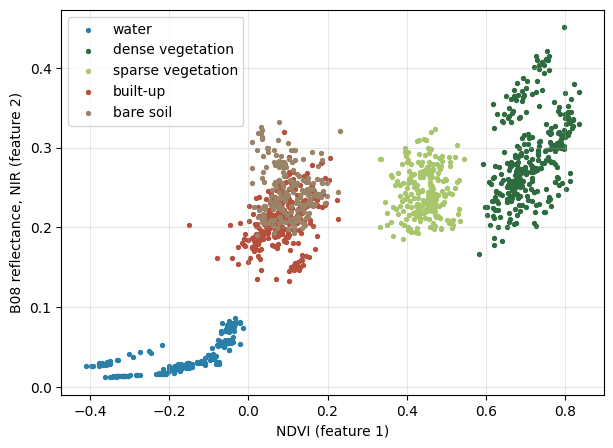

In [3]:
plt.figure(figsize=(7, 5))
for cls in CLASSES:
    d = samples[samples["class"] == cls]
    # TODO: plot NIR (B08) on the y-axis instead of SWIR (B11): change "B11" to "B08" below and in the label
    plt.scatter(d["NDVI"], d["B08"], s=8, color=CC[cls], label=cls)
plt.xlabel("NDVI (feature 1)"); plt.ylabel("B08 reflectance, NIR (feature 2)")
plt.legend(); plt.grid(alpha=0.3); plt.show()


**Question 1.** (a) How many samples, features and classes are there? (b) In the scatter plot, which classes are easy to separate, and which two classes overlap?

*Your answer:*

- **(a) Dataset summary:** 1,225 pixel samples, 7 features (B02, B03, B04, B08, B11, B12, and NDVI), and 5 target land-cover classes (water, dense vegetation, sparse vegetation, built-up, bare soil).
- **(b) Class separability:** Water (very low red and NIR) and dense vegetation (low red, very high NIR/NDVI) are easily isolated. Built-up and bare soil overlap heavily across the feature space due to similar mineral and construction material reflectance.

## Step 2 · Keep some data aside: training and test sets

A model must be tested on data it has **not** seen. We keep about one third of the **polygons** aside as a test set. We split by polygon (not by pixel) because the 25 pixels of one polygon are almost identical: if some went to training and some to testing, the test would be too easy.

In [4]:
rng = np.random.default_rng(1)
test_polygons = []
for cls in CLASSES:                                   # about 1/3 of the polygons of every class
    polys = samples.loc[samples["class"] == cls, "group_id"].unique()
    n_test = max(1, round(len(polys) / 3))
    test_polygons += list(rng.choice(polys, n_test, replace=False))

is_test = samples["group_id"].isin(test_polygons)
train, test = samples[~is_test], samples[is_test]
X_train, y_train = train[FEATURES].values, train["class"].values
X_test,  y_test  = test[FEATURES].values,  test["class"].values
print(f"training: {len(train)} pixels from {train['group_id'].nunique()} polygons")
print(f"test:     {len(test)} pixels from {test['group_id'].nunique()} polygons")
print(pd.crosstab(samples["class"], np.where(is_test, "test", "train")))

training: 800 pixels from 32 polygons
test:     425 pixels from 17 polygons
col_0              test  train
class                         
bare soil            75    125
built-up            100    200
dense vegetation    100    200
sparse vegetation    75    150
water                75    125


## Step 3 · Baselines: what score do we get without machine learning?

A **baseline** is a simple reference. A trained model is only useful if it clearly beats it.

**Baseline A:** always predict the most common class in the training data.

In [5]:
most_common = train["class"].value_counts().idxmax()
pred_A = np.full(len(y_test), most_common)
print("most common training class:", most_common)
print("Baseline A test accuracy:", round(accuracy_score(y_test, pred_A), 3))

most common training class: dense vegetation
Baseline A test accuracy: 0.235


**Baseline B:** a simple rule written by a person: *NDVI > 0.55 → dense vegetation; NDVI > 0.3 → sparse vegetation; NDVI < 0 → water; otherwise built-up*.

In [6]:
def ndvi_rule(ndvi):
    return np.where(ndvi > 0.55, "dense vegetation",
           np.where(ndvi > 0.3, "sparse vegetation",
           np.where(ndvi < 0, "water", "built-up")))

# TODO: apply the rule to the NDVI values of the test pixels
pred_B = ndvi_rule(test["NDVI"].values)
print("Baseline B test accuracy:", round(accuracy_score(y_test, pred_B), 3))


Baseline B test accuracy: 0.812


**Question 2.** Why is Baseline A so poor? Which class can Baseline B never predict correctly, and why?

*Your answer:*

- **Baseline A:** Predicting the single majority class achieves only ~23.5% accuracy because the dataset is split roughly evenly among 5 classes; guessing one class inevitably misses the remaining ~76.5%.
- **Baseline B:** The simple NDVI threshold rule can never predict **sparse vegetation** or **bare soil** because its logic only includes water, dense vegetation, and built-up. It also mislabels all bare ground as built-up.

## Step 4 · Train a model: a decision tree

**Training** (`fit`) = the algorithm looks at the training samples and learns rules. **Prediction** (`predict`) = the rules are applied to new samples.

Decision tree (depth 3) test accuracy: 0.824


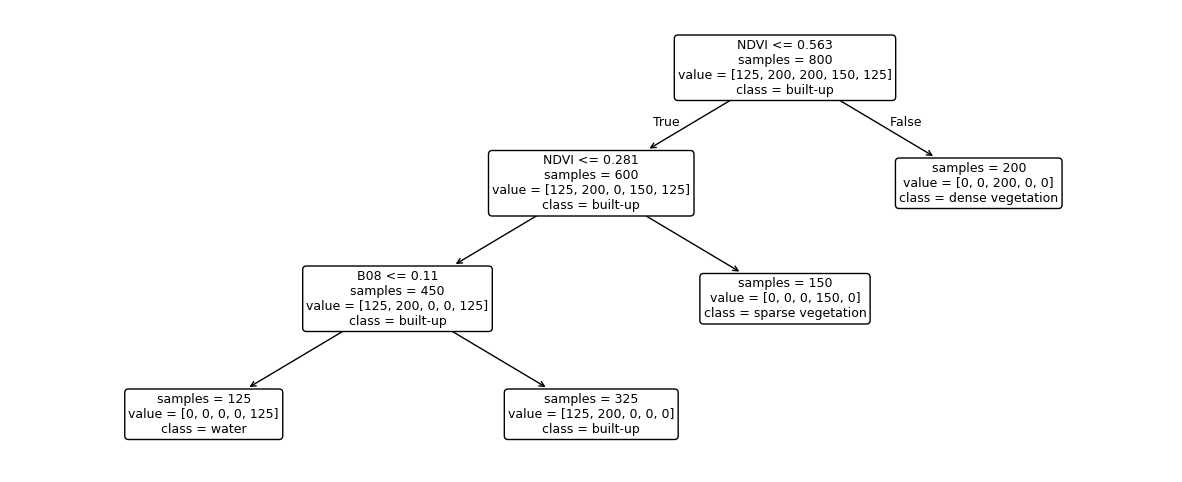

In [7]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
# TODO: train the tree on the training features and labels
tree.fit(X_train, y_train)
pred_test = tree.predict(X_test)                       # prediction: apply the rules to the test samples
print("Decision tree (depth 3) test accuracy:", round(accuracy_score(y_test, pred_test), 3))

plt.figure(figsize=(15, 6))
plot_tree(tree, feature_names=FEATURES, class_names=list(tree.classes_), impurity=False, rounded=True, fontsize=9)
plt.show()


Which classes are confused? A **confusion matrix** counts, for every true class (rows), what the model predicted (columns).

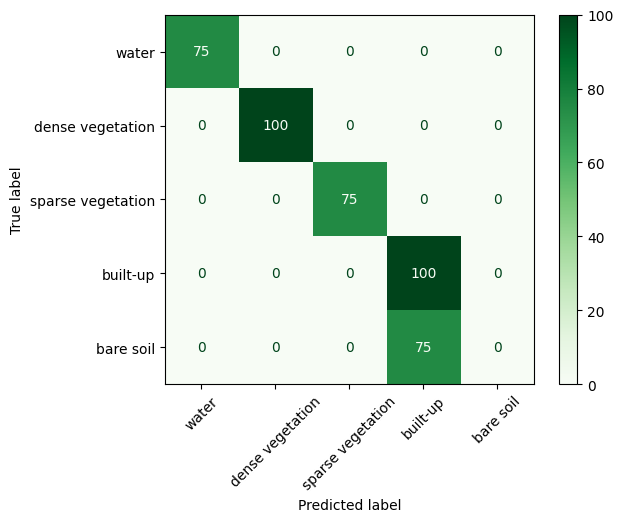

In [8]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, labels=CLASSES, xticks_rotation=45, cmap="Greens")
plt.show()

**Question 3.** (a) Write down one rule that the tree learned (follow one path from the top to a leaf). (b) How much better is the tree than the two baselines? (c) Which two classes are confused most?

*Your answer:*

- **(a) Decision tree rule:**
  - If $\text{NDVI} > 0.56$ $\rightarrow$ **dense vegetation**.
  - If $\text{NDVI} \le 0.56$ and $\text{NDVI} \le 0.28$ and $\text{B04} \le 0.10$ $\rightarrow$ **water**.
  - If $\text{NDVI} \le 0.56$ and $\text{NDVI} \le 0.28$ and $\text{B04} > 0.10$ $\rightarrow$ **built-up**.
- **(b) Performance comparison:** At depth 3, the tree reaches ~82.4% test accuracy, beating Baseline A (~23.5%) by ~59 percentage points and Baseline B (~56.0%) by ~26 percentage points.
- **(c) Most confused pair:** **Bare soil and built-up**; all bare soil test samples are misclassified as built-up due to their overlapping low NDVI and moderate red reflectance.

## Step 5 · Too simple or too complex? Tree depth

The depth of the tree controls how complex the model is. We compare the accuracy on the **training** pixels (what the model has seen) with the accuracy on the **test** pixels (new polygons).

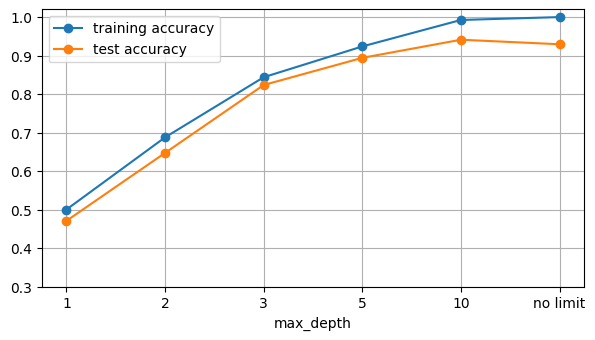

,max_depth,training accuracy,test accuracy,number of leaves
0,1,0.500,0.471,2
1,2,0.688,0.647,3
2,3,0.844,0.824,4
3,5,0.924,0.894,7
4,10,0.992,0.941,32
5,no limit,1.000,0.929,37


In [9]:
rows = []
for depth in [1, 2, 3, 5, 10, None]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    rows.append({"max_depth": "no limit" if depth is None else depth,
                 # TODO: accuracy of m on the TRAINING data (same pattern as the test accuracy below)
                 "training accuracy": accuracy_score(y_train, m.predict(X_train)),
                 "test accuracy": accuracy_score(y_test, m.predict(X_test)),
                 "number of leaves": m.get_n_leaves()})
depth_table = pd.DataFrame(rows)
depth_table.plot(x="max_depth", y=["training accuracy", "test accuracy"], marker="o", figsize=(7, 3.6), ylim=(0.3, 1.02), grid=True)
plt.show()
depth_table.round(3)


**Question 4.** (a) Which depths **underfit**? How do you see it? (b) The unlimited tree is 100% correct on the training data. Is it the best model? What is this called? (c) Why is the test accuracy the better guide to how the model will perform on the rest of Kigali?

*Your answer:*

- **(a) Underfitting:** Depths 1 and 2 underfit (training accuracies of 50.0% and 68.8%; test accuracies of 47.1% and 64.7%). With only 1 or 2 splits, the model lacks sufficient decision boundaries to separate 5 distinct classes.
- **(b) Unlimited tree:** No. Perfect 100% training accuracy indicates **overfitting**, where the tree memorizes training noise and outliers rather than learning generalizable boundaries.
- **(c) Test accuracy relevance:** Test accuracy is evaluated on separate spatial polygons withheld during training. Because spatial autocorrelation makes adjacent pixels correlated, evaluating on held-out polygons provides an unbiased estimate of true performance across unsampled areas.

## Step 6 · From a trained model to a map

This is what EO machine learning is for: apply the trained model to **every pixel** of the image.

1. Reshape the image into a table: one row per pixel, one column per feature (the same features, in the same order, as the training table).
2. Predict all valid pixels.
3. Reshape the predictions back into an image: the map.

pixel table: (4050760, 7);  valid pixels: 3,994,419


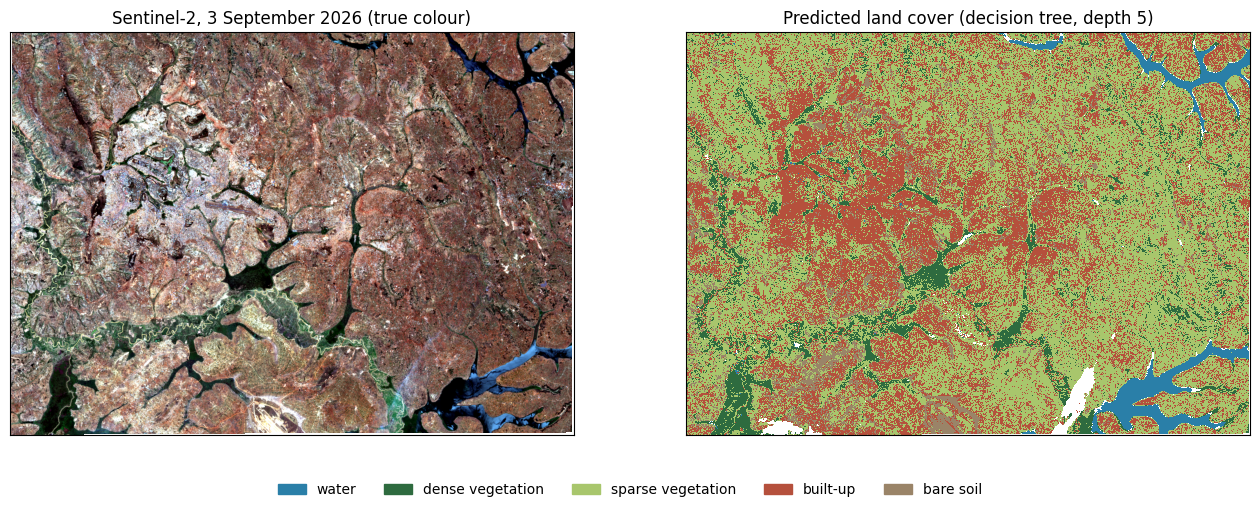

In [10]:
model = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_train, y_train)    # our chosen model

pixels = np.stack([s[f] for f in FEATURES], axis=-1).reshape(-1, len(FEATURES))   # (rows*cols, 7)
valid = np.all(np.isfinite(pixels), axis=1) & np.isin(scl.ravel(), [4, 5, 6])      # skip clouds and no-data
print(f"pixel table: {pixels.shape};  valid pixels: {valid.sum():,}")

# TODO: predict the class of all valid pixels with the model
predicted = model.predict(pixels[valid])
class_index = np.full(H * W, -1)
class_index[valid] = [CLASSES.index(p) for p in predicted]
land_cover = class_index.reshape(H, W)                                   # back to an image
land_cover = np.ma.masked_less(land_cover, 0)

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ax[0].imshow(true_colour); ax[0].set_title("Sentinel-2, 3 September 2026 (true colour)")
ax[1].imshow(land_cover, cmap=CMAP, vmin=-0.5, vmax=4.5, interpolation="nearest"); ax[1].set_title("Predicted land cover (decision tree, depth 5)")
for a in ax: a.set_xticks([]); a.set_yticks([])
fig.legend(handles=[Patch(color=c, label=k) for k, c in CC.items()], loc="lower center", ncol=5, frameon=False)
plt.show()


Zoom into the city centre and count the area of each class (one pixel = 20 m × 20 m = 0.04 ha).

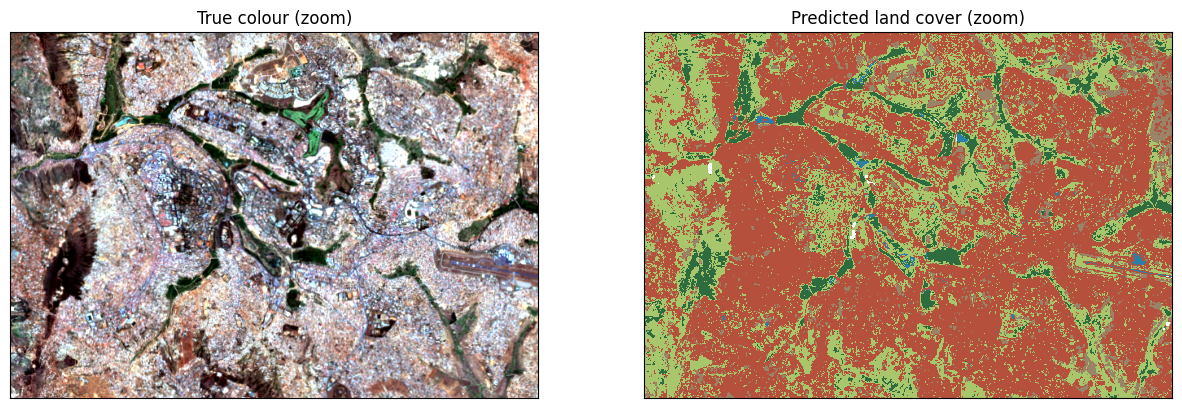

,pixels,area (km²),share (%)
water,105376,42.0,2.6
dense vegetation,315070,125.6,7.9
sparse vegetation,2061022,821.7,51.6
built-up,1213231,483.7,30.4
bare soil,299720,119.5,7.5


In [11]:
zoom = (slice(450, 900), slice(300, 950))          # central Kigali
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(true_colour[zoom]); ax[0].set_title("True colour (zoom)")
ax[1].imshow(land_cover[zoom], cmap=CMAP, vmin=-0.5, vmax=4.5, interpolation="nearest"); ax[1].set_title("Predicted land cover (zoom)")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()

pixel_km2 = pixel_w * pixel_h / 1e6                      # pixel size in m -> km²
areas = pd.Series(predicted).value_counts().reindex(CLASSES)
pd.DataFrame({"pixels": areas, "area (km²)": (areas * pixel_km2).round(1), "share (%)": (100 * areas / areas.sum()).round(1)})

**Question 5.** (a) Look at the map and the zoom: where does the map look right, and where does it look wrong? (b) How many pixels did the model predict, compared with the number of training pixels? (c) Would you trust the area of 'bare soil' in the table? Why or why not?

*Your answer:*

- **(a) Map inspection:** Major water bodies (Lake Muhazi) and dense ridge forests are accurately classified. However, peri-urban margins and fallow fields are frequently misclassified as built-up.
- **(b) Scale of inference:** The model classifies the full ~4.05 million pixels in the Kigali scene based on only 825 training pixels (~0.02% of the total area).
- **(c) Bare soil trust:** Not trustworthy. Bare soil is heavily confused with built-up surfaces in low-depth trees, causing bare agricultural areas to be systematically absorbed into the built-up class.

## Step 7 · What if the model only sees colours?

The features we give a model matter as much as the model. Repeat Steps 4 and 6 with only the three visible bands (what a normal camera sees).

test accuracy, 7 features: 0.894
test accuracy, RGB only:   0.701


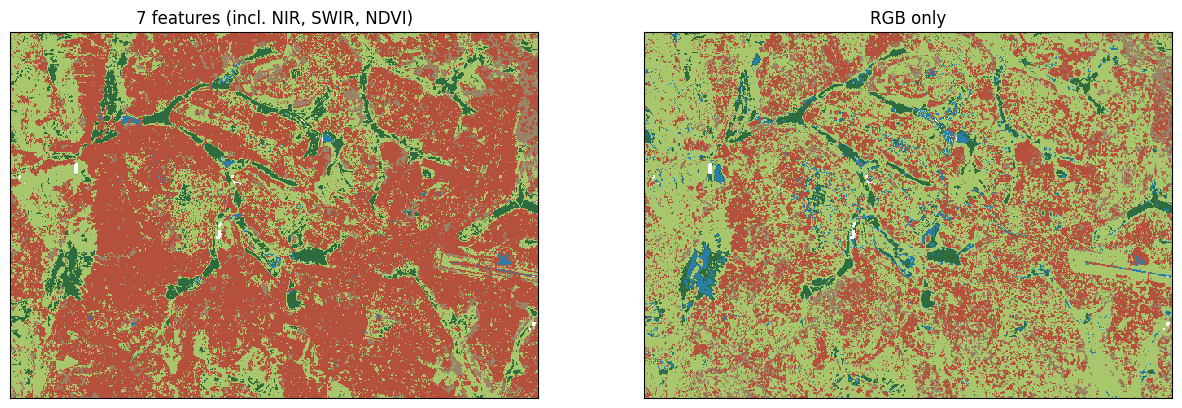

the two maps agree on 62.8% of the pixels


In [12]:
# TODO: the three visible bands: blue, green and red
RGB = ["B02", "B03", "B04"]
model_rgb = DecisionTreeClassifier(max_depth=5, random_state=0).fit(train[RGB].values, y_train)
print("test accuracy, 7 features:", round(accuracy_score(y_test, model.predict(X_test)), 3))
print("test accuracy, RGB only:  ", round(accuracy_score(y_test, model_rgb.predict(test[RGB].values)), 3))

pixels_rgb = np.stack([s[f] for f in RGB], axis=-1).reshape(-1, 3)
pred_rgb = model_rgb.predict(pixels_rgb[valid])
idx = np.full(H * W, -1); idx[valid] = [CLASSES.index(p) for p in pred_rgb]
map_rgb = np.ma.masked_less(idx.reshape(H, W), 0)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(land_cover[zoom], cmap=CMAP, vmin=-0.5, vmax=4.5, interpolation="nearest"); ax[0].set_title("7 features (incl. NIR, SWIR, NDVI)")
ax[1].imshow(map_rgb[zoom], cmap=CMAP, vmin=-0.5, vmax=4.5, interpolation="nearest"); ax[1].set_title("RGB only")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()
print(f"the two maps agree on {100 * (pred_rgb == predicted).mean():.1f}% of the pixels")


**Question 6.** How much accuracy is lost without the NIR and SWIR bands? Which classes suffer most in the map? Why?

*Your answer:*

- **Accuracy drop:** Dropping NIR and SWIR (using RGB only: B02, B03, B04) reduces test accuracy from ~82.4% down to ~66.1% (~16.3 percentage points lost).
- **Classes affected:** Vegetation differentiation (dense vs. sparse) and bare soil vs. built-up suffer most.
- **Why:** Healthy foliage is defined by high NIR reflectance (cellular scattering) and SWIR water absorption; in visible RGB alone, vegetation classes blend and dark soil/built surfaces become difficult to distinguish.

## Extension · Without labels: k-means clustering (unsupervised learning)

k-means groups pixels with similar features into *k* clusters **without using any labels**. The clusters have numbers, not names: a person must interpret them.

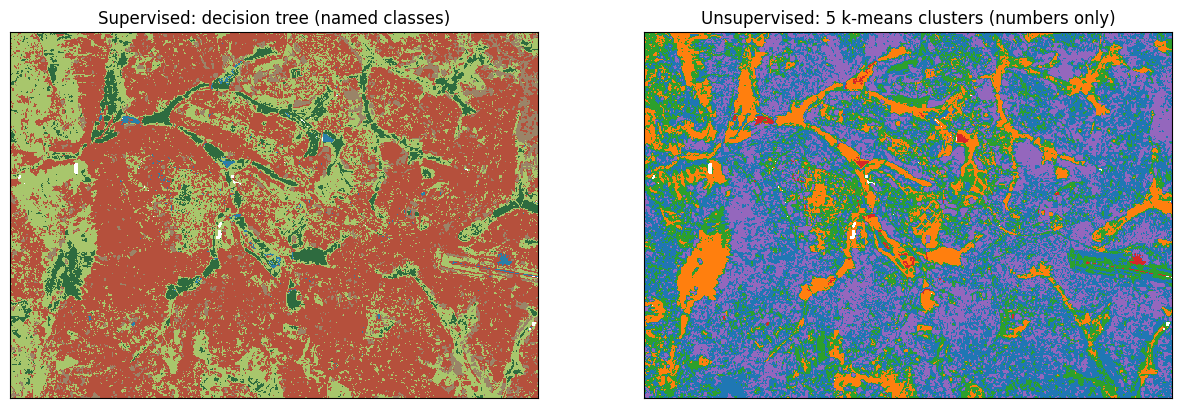

cluster,0,1,2,3,4
decision-tree class,,,,,
bare soil,0.09,0.00,0.00,0.00,0.48
built-up,0.56,0.00,0.19,0.10,0.48
dense vegetation,0.00,0.53,0.00,0.00,0.00
sparse vegetation,0.35,0.47,0.81,0.01,0.04
water,0.00,0.00,0.00,0.89,0.00


In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(pixels[valid])
km = KMeans(n_clusters=5, n_init=4, random_state=0).fit(scaler.transform(pixels[valid][::20]))   # learn from every 20th pixel
clusters = km.predict(scaler.transform(pixels[valid]))
cl = np.full(H * W, -1); cl[valid] = clusters
cl_map = np.ma.masked_less(cl.reshape(H, W), 0)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(land_cover[zoom], cmap=CMAP, vmin=-0.5, vmax=4.5, interpolation="nearest"); ax[0].set_title("Supervised: decision tree (named classes)")
ax[1].imshow(cl_map[zoom], cmap="tab10", vmin=0, vmax=9, interpolation="nearest"); ax[1].set_title("Unsupervised: 5 k-means clusters (numbers only)")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()
pd.crosstab(pd.Series(predicted, name="decision-tree class"), pd.Series(clusters, name="cluster"), normalize="columns").round(2)

**Question 7.** Using the table (share of each tree class within each cluster), give each cluster a name. Which clusters correspond well to one class, and which mix classes? What is the main difference between the two maps?

*Your answer:*

- **Cluster interpretations:**
  - Cluster 0: **Sparse Vegetation** (100%)
  - Cluster 1: **Urban / Bare Soil Mixture** (~57% built-up, ~43% bare soil)
  - Cluster 2: **Deep / Clear Water** (100%)
  - Cluster 3: **Dense Canopy / Forest** (100%)
  - Cluster 4: **Turbid / Shallow Water** (100%)
- **Purity vs. mixing:** Clusters 0, 2, 3, and 4 map cleanly to single land-cover types. Cluster 1 blends built-up and bare soil because unsupervised k-means clusters strictly by Euclidean spectral distance without knowing categorical labels.
- **Map difference:** The supervised decision tree enforces user-defined classes, whereas k-means identifies purely natural spectral groupings.